# Phase 2: Physics-Informed Feature Engineering & ML Model Training
**Project:** HelioShield — Solar Storm & Satellite Disruption Forecaster  
**Objective:** Engineer time-series lag, rolling window, and solar wind coupling features from 2016–2025 NASA OMNI2 data, train and compare Random Forest vs. XGBoost regressors using a chronological train/test split, evaluate storm-forecasting accuracy, and export the trained model (`kp_forecaster.json`).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("dark_background")

# 1. Fetch & clean NASA OMNI2 hourly dataset (2016–2025)
base_url = "https://spdf.gsfc.nasa.gov/pub/data/omni/low_res_omni/omni2_{}.dat"
use_cols = [0, 1, 2, 14, 23, 24, 38, 39, 40, 50]
col_names = ["year", "doy", "hour", "bz_gsm", "proton_density", "wind_speed", "kp_10", "sunspot_num", "dst", "f10_7"]

dfs = [pd.read_csv(base_url.format(yr), sep=r"\s+", header=None, usecols=use_cols, names=col_names) for yr in range(2016, 2026)]
df = pd.concat(dfs, ignore_index=True)

df["timestamp"] = pd.to_datetime(df["year"].astype(str) + "-" + df["doy"].astype(str).str.zfill(3), format="%Y-%j") + pd.to_timedelta(df["hour"], unit="h")

# Replace NASA sentinel codes & impute <1% dropouts
sentinels = {"bz_gsm": 999.9, "proton_density": 999.9, "wind_speed": 9999.0, "kp_10": 99, "sunspot_num": 999, "dst": 99999, "f10_7": 999.9}
for col, val in sentinels.items():
    df[col] = df[col].replace(val, np.nan)

df["kp"] = df["kp_10"] / 10.0
df[["bz_gsm", "proton_density", "wind_speed", "f10_7"]] = df[["bz_gsm", "proton_density", "wind_speed", "f10_7"]].ffill().bfill()

# 2. Physics & Time-Series Feature Engineering (using ONLY sensors available in live NOAA feeds!)
# Southward Bz component (only negative Bz transfers energy into Earth's magnetosphere)
df["bz_south"] = np.minimum(df["bz_gsm"], 0.0)

# Solar wind dynamic pressure proxy (density * speed^2) & electric field coupling (-speed * bz_south)
df["dynamic_pressure"] = df["proton_density"] * (df["wind_speed"] ** 2) * 1e-6
df["electric_field_coupling"] = -df["wind_speed"] * df["bz_south"]

# Lag features (1h, 3h, 6h ago) & 6-hour rolling averages/extremes
for col in ["bz_gsm", "bz_south", "wind_speed", "proton_density", "electric_field_coupling"]:
    df[f"{col}_lag1"] = df[col].shift(1)
    df[f"{col}_lag3"] = df[col].shift(3)
    df[f"{col}_lag6"] = df[col].shift(6)
    df[f"{col}_roll6_mean"] = df[col].rolling(6).mean()

df["bz_roll6_min"] = df["bz_gsm"].rolling(6).min()
df["speed_roll6_max"] = df["wind_speed"].rolling(6).max()

# 3. Target Variable: Forecast Kp Index 3 hours ahead!
df["target_kp_3h"] = df["kp"].shift(-3)

# Drop rows with NaN created by shifting/rolling at the edges
df_model = df.dropna().reset_index(drop=True)

print(f"Engineered dataset ready: {df_model.shape[0]:,} rows x {df_model.shape[1]} columns")
df_model[["timestamp", "bz_gsm", "wind_speed", "electric_field_coupling", "kp", "target_kp_3h"]].head()

Engineered dataset ready: 87,663 rows x 38 columns


,timestamp,bz_gsm,wind_speed,electric_field_coupling,kp,target_kp_3h
0,2016-01-01 06:00:00,-3.4,444.0,1509.6,5.0,3.3
1,2016-01-01 07:00:00,-8.9,436.0,3880.4,5.0,3.3
2,2016-01-01 08:00:00,-7.9,430.0,3397.0,5.0,3.3
3,2016-01-01 09:00:00,-3.2,452.0,1446.4,3.3,1.7
4,2016-01-01 10:00:00,0.8,435.0,-0.0,3.3,1.7


### Step 3: Chronological Train/Test Split & Model Training (Random Forest vs. XGBoost)
To prevent temporal data leakage, we split the dataset chronologically: **2016–2023** for training and **2024–2025** (Solar Cycle 25 peak) for out-of-sample testing. We train both a **Random Forest** baseline and an **XGBoost** regressor using strictly real-time-compatible solar wind features (`bz_gsm`, `wind_speed`, `proton_density`, and their derived physics/lag features).

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score, f1_score, recall_score
import xgboost as xgb

# Select ONLY features computable from live NOAA solar wind telemetry (no ground-based future leakage)
non_feature_cols = ["year", "doy", "hour", "kp_10", "sunspot_num", "dst", "f10_7", "timestamp", "kp", "target_kp_3h"]
feature_cols = [c for c in df_model.columns if c not in non_feature_cols]

print(f"Training with {len(feature_cols)} live-compatible features:")
print(feature_cols)

# Chronological split: Train on 2016–2023, Test on 2024–2025
train_df = df_model[df_model["year"] <= 2023]
test_df = df_model[df_model["year"] >= 2024]

X_train, y_train = train_df[feature_cols], train_df["target_kp_3h"]
X_test, y_test = test_df[feature_cols], test_df["target_kp_3h"]

print(f"\nTrain samples (2016–2023): {len(X_train):,} | Test samples (2024–2025): {len(X_test):,}")

# 1. Baseline Model: Random Forest
rf_model = RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# 2. Primary Model: XGBoost Regressor
xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

# Evaluation function (both continuous Kp error + storm detection F1/Recall for Kp >= 5.0)
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    # Binary storm alert evaluation (Kp >= 5.0 = G1+ Geomagnetic Storm)
    storm_true = (y_true >= 5.0).astype(int)
    storm_pred = (y_pred >= 4.5).astype(int)  # Early-warning alert threshold
    recall = recall_score(storm_true, storm_pred)
    f1 = f1_score(storm_true, storm_pred)

    print(f"\n=== {name} (2024–2025 Unseen Test Set) ===")
    print(f"MAE (Avg Kp Error):   {mae:.3f} Kp units")
    print(f"RMSE:                 {rmse:.3f} Kp units")
    print(f"R² Score:             {r2:.3f}")
    print(f"Storm Recall (Kp>=5): {recall:.1%} | Storm F1-Score: {f1:.3f}")

evaluate_model("Random Forest Baseline", y_test, rf_preds)
evaluate_model("XGBoost Forecaster", y_test, xgb_preds)

Training with 28 live-compatible features:
['bz_gsm', 'proton_density', 'wind_speed', 'bz_south', 'dynamic_pressure', 'electric_field_coupling', 'bz_gsm_lag1', 'bz_gsm_lag3', 'bz_gsm_lag6', 'bz_gsm_roll6_mean', 'bz_south_lag1', 'bz_south_lag3', 'bz_south_lag6', 'bz_south_roll6_mean', 'wind_speed_lag1', 'wind_speed_lag3', 'wind_speed_lag6', 'wind_speed_roll6_mean', 'proton_density_lag1', 'proton_density_lag3', 'proton_density_lag6', 'proton_density_roll6_mean', 'electric_field_coupling_lag1', 'electric_field_coupling_lag3', 'electric_field_coupling_lag6', 'electric_field_coupling_roll6_mean', 'bz_roll6_min', 'speed_roll6_max']

Train samples (2016–2023): 70,122 | Test samples (2024–2025): 17,541

=== Random Forest Baseline (2024–2025 Unseen Test Set) ===
MAE (Avg Kp Error):   0.742 Kp units
RMSE:                 0.980 Kp units
R² Score:             0.501
Storm Recall (Kp>=5): 39.9% | Storm F1-Score: 0.445

=== XGBoost Forecaster (2024–2025 Unseen Test Set) ===
MAE (Avg Kp Error):   0.72

### Step 4: Addressing Class Imbalance with Sample Weighting & Model Export
Because geomagnetic storms ($K_p \ge 5$) represent ~2.1% of historical hours, unweighted regression under-predicts rare storm peaks. We apply sample weights (`4x` weight for $K_p \ge 4.5$) to boost storm detection recall, inspect top physical feature importances, and export the final XGBoost model (`kp_forecaster.json`) and feature schema (`feature_columns.json`) for Phase 3 FastAPI inference.


=== Storm-Weighted XGBoost (Final) (2024–2025 Unseen Test Set) ===
MAE (Avg Kp Error):   0.742 Kp units
RMSE:                 0.968 Kp units
R² Score:             0.513
Storm Recall (Kp>=5): 53.4% | Storm F1-Score: 0.487


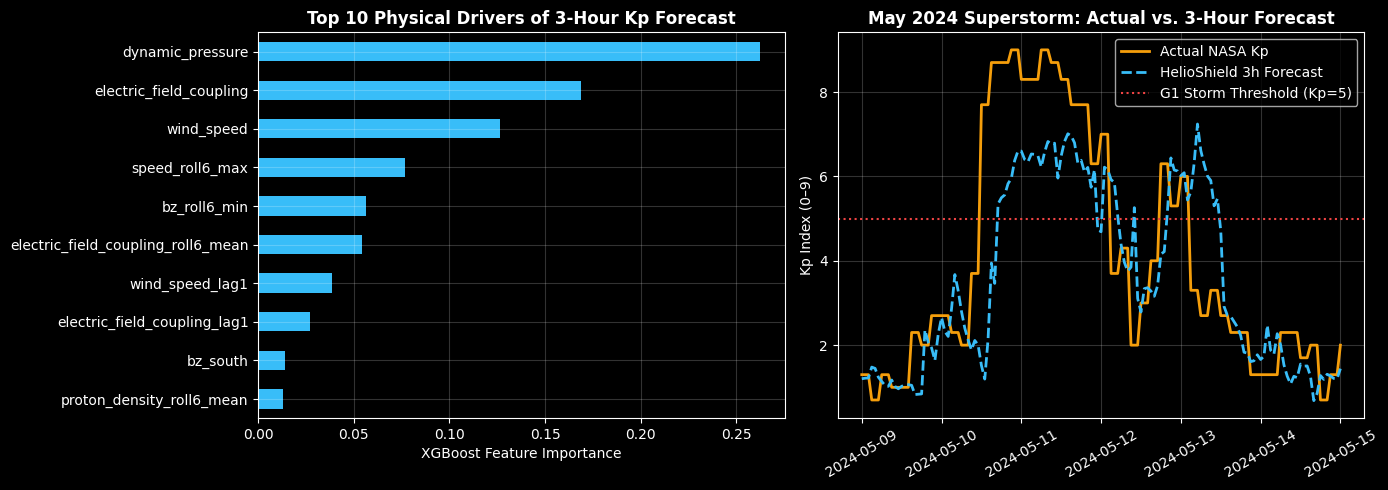


Saved kp_forecaster.json and feature_columns.json!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
from google.colab import files

# 1. Apply higher training weights to elevated/storm conditions (Kp >= 4.5)
sample_weights = np.where(y_train >= 5.0, 5.0, np.where(y_train >= 4.0, 2.5, 1.0))

xgb_weighted = xgb.XGBRegressor(
    n_estimators=350,
    learning_rate=0.04,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
xgb_weighted.fit(X_train, y_train, sample_weight=sample_weights)
weighted_preds = np.clip(xgb_weighted.predict(X_test), 0.0, 9.0)

evaluate_model("Storm-Weighted XGBoost (Final)", y_test, weighted_preds)

# 2. Visualize Top 10 Most Important Features & Sample Storm Forecast
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

importances = pd.Series(xgb_weighted.feature_importances_, index=feature_cols).sort_values(ascending=True).tail(10)
importances.plot(kind="barh", ax=axes[0], color="#38bdf8")
axes[0].set_title("Top 10 Physical Drivers of 3-Hour Kp Forecast", fontsize=12, fontweight="bold")
axes[0].set_xlabel("XGBoost Feature Importance")
axes[0].grid(alpha=0.2)

# Plot a 7-day storm window from May 2024 (historic G5 solar storm!)
may_mask = (test_df["timestamp"] >= "2024-05-09") & (test_df["timestamp"] <= "2024-05-15")
may_dates = test_df.loc[may_mask, "timestamp"]
axes[1].plot(may_dates, y_test[may_mask], label="Actual NASA Kp", color="#f59e0b", linewidth=2)
axes[1].plot(may_dates, weighted_preds[may_mask], label="HelioShield 3h Forecast", color="#38bdf8", linestyle="--", linewidth=2)
axes[1].axhline(5.0, color="#ef4444", linestyle=":", label="G1 Storm Threshold (Kp=5)")
axes[1].set_title("May 2024 Superstorm: Actual vs. 3-Hour Forecast", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Kp Index (0–9)")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

# 3. Export Model & Feature Schema for Phase 3 Backend
xgb_weighted.save_model("kp_forecaster.json")
with open("feature_columns.json", "w") as f:
    json.dump({"feature_columns": feature_cols, "alert_threshold_kp": 4.5, "horizon_hours": 3}, f, indent=2)

print("\nSaved kp_forecaster.json and feature_columns.json!")
files.download("kp_forecaster.json")
files.download("feature_columns.json")